# Clustering Player Style Profiles

This notebook evaluates whether the DGVT player profiles form distinct play-style archetypes. It starts with a two-cluster solution, compares K-means and Gaussian mixtures, checks whether clusters mostly reproduce skill or variance, tests the profile threshold and feature choices, and uses PCA as a continuous style-dimensions fallback.

The profile window is 2020-2023. Only usable rounds by players with a PDGA number and event-time rating enter profiles. The primary threshold is at least 2 events, 4 rounds, and 72 holes.

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dgvt_styles').is_dir())
FEATURE_PATH = ROOT / 'dgvt_styles' / 'build_hole_features' / 'output' / 'hole_features.csv'
features = pd.read_csv(FEATURE_PATH, dtype={'player_key': str})
features = features[(features['year'].between(2020, 2023)) & features['in_training']].copy()

PROFILE_FEATURES = [
    'sg_short', 'sg_medium', 'sg_long', 'sg_par3_minus_par4plus',
    'pct_birdie_or_better', 'pct_par', 'pct_bogey', 'pct_double_or_worse',
    'hole_volatility', 'round_sd_18',
]
STYLE_FEATURES = [f'{name}_vs_skill' for name in PROFILE_FEATURES]

print(f'{len(features):,} usable rated hole scores in the profile window')

195,570 usable rated hole scores in the profile window


In [10]:
def build_profiles(df, min_events=2, min_rounds=4, min_holes=72, shrink_holes=50):
    df = df[df['in_training']].copy()
    player_rounds = df.groupby(['player_key', 'event_id', 'round']).agg(
        round_sg_18=('round_sg_avg', 'first'),
        rating=('event_rating', 'first'),
    )
    player_rounds['round_sg_18'] *= 18
    summary = player_rounds.groupby('player_key').size().rename('n_rounds').to_frame()
    summary['n_events'] = df.groupby('player_key')['event_id'].nunique()
    summary['n_holes'] = df.groupby('player_key').size()
    keep = summary.index[
        (summary['n_events'] >= min_events)
        & (summary['n_rounds'] >= min_rounds)
        & (summary['n_holes'] >= min_holes)
    ]
    df = df[df['player_key'].isin(keep)]
    player_rounds = player_rounds[player_rounds.index.get_level_values('player_key').isin(keep)]
    players = df.groupby('player_key')
    profiles = pd.DataFrame({
        'n_events': summary.loc[keep, 'n_events'],
        'n_rounds': summary.loc[keep, 'n_rounds'],
        'n_holes': summary.loc[keep, 'n_holes'],
        'rating': player_rounds.groupby('player_key')['rating'].median(),
        'sg_per_18': players['strokes_gained'].mean() * 18,
    })
    by_type = df.groupby(['player_key', 'hole_type'], observed=True)['sg_style_adj'].agg(['sum', 'size'])
    shrunk = (by_type['sum'] / (by_type['size'] + shrink_holes)).unstack().fillna(0)
    for hole_type in ['short', 'medium', 'long']:
        profiles[f'sg_{hole_type}'] = shrunk[hole_type]
    by_par = (df.assign(par_group=np.where(df['par'] == 3, 'par3', 'par4plus'))
              .groupby(['player_key', 'par_group'])['sg_style_adj'].agg(['sum', 'size']))
    shrunk_par = (by_par['sum'] / (by_par['size'] + shrink_holes)).unstack().fillna(0)
    profiles['sg_par3_minus_par4plus'] = shrunk_par['par3'] - shrunk_par['par4plus']
    to_par = df['score_to_par']
    mix = pd.DataFrame({
        'pct_birdie_or_better': to_par <= -1,
        'pct_par': to_par == 0,
        'pct_bogey': to_par == 1,
        'pct_double_or_worse': to_par >= 2,
    }).groupby(df['player_key']).mean()
    profiles = profiles.join(mix)
    profiles['hole_volatility'] = players['sg_style_adj'].std()
    profiles['round_sd_18'] = player_rounds.groupby('player_key')['round_sg_18'].std()
    return profiles, summary, keep

def add_skill_adjusted(profiles):
    profiles = profiles.copy()
    for name in PROFILE_FEATURES:
        complete = profiles[[name, 'sg_per_18']].dropna()
        fit = np.polyfit(complete['sg_per_18'], complete[name], deg=2)
        profiles.loc[complete.index, f'{name}_vs_skill'] = complete[name] - np.polyval(fit, complete['sg_per_18'])
    return profiles

profiles_2, eligible_summary, keep_2 = build_profiles(features, min_events=2, min_rounds=4, min_holes=72)
profiles_2 = add_skill_adjusted(profiles_2)
print(f'Eligible rated players: {len(eligible_summary):,}')
print(f'Retained for primary clustering: {len(keep_2):,}')
print(profiles_2[['n_events', 'n_rounds', 'n_holes']].describe().round(1))

Eligible rated players: 1,055
Retained for primary clustering: 604
       n_events  n_rounds  n_holes
count     604.0     604.0    604.0
mean        7.6      16.2    290.9
std         7.9      16.0    288.1
min         2.0       4.0     72.0
25%         2.0       6.0    108.0
50%         4.0       9.5    171.0
75%         9.0      20.0    360.0
max        46.0      95.0   1710.0


## Step 1: start with two clusters

Two clusters are the most conservative first test. If even a two-group solution does not separate cleanly, more clusters are unlikely to represent robust archetypes.

In [11]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

cluster_profiles = profiles_2[STYLE_FEATURES].dropna().copy()
X = StandardScaler().fit_transform(cluster_profiles)

models_2 = {}
for model_name in ['K-means', 'Gaussian mixture']:
    if model_name == 'K-means':
        model = KMeans(n_clusters=2, n_init=50, random_state=0)
        labels = model.fit_predict(X)
        bic = np.nan
    else:
        model = GaussianMixture(n_components=2, n_init=10, reg_covar=1e-5, random_state=0)
        labels = model.fit_predict(X)
        bic = model.bic(X)
    models_2[model_name] = (model, labels)
    print(f'{model_name}: silhouette={silhouette_score(X, labels):.3f}; BIC={bic if not np.isnan(bic) else "n/a"}')

kmeans_labels = models_2['K-means'][1]
gmm_labels = models_2['Gaussian mixture'][1]
print(f'Agreement between two-cluster solutions: ARI={adjusted_rand_score(kmeans_labels, gmm_labels):.3f}')
print('K-means sizes:', pd.Series(kmeans_labels).value_counts().sort_index().to_dict())
print('GMM sizes:', pd.Series(gmm_labels).value_counts().sort_index().to_dict())

K-means: silhouette=0.165; BIC=n/a
Gaussian mixture: silhouette=0.158; BIC=8877.871357716875
Agreement between two-cluster solutions: ARI=0.585
K-means sizes: {0: 390, 1: 214}
GMM sizes: {0: 194, 1: 410}


## Step 2: compare clusters with skill and performance

A useful cluster solution should not merely recreate the rating ladder. These plots compare cluster membership with event-time rating, SG per 18, and the two variance measures.

,n_players,median_rating,median_sg_per_18,median_round_sd_18,median_hole_volatility
cluster,,,,,
0,194,914.75,0.660,4.489,0.822
1,410,888.25,0.891,4.000,0.728


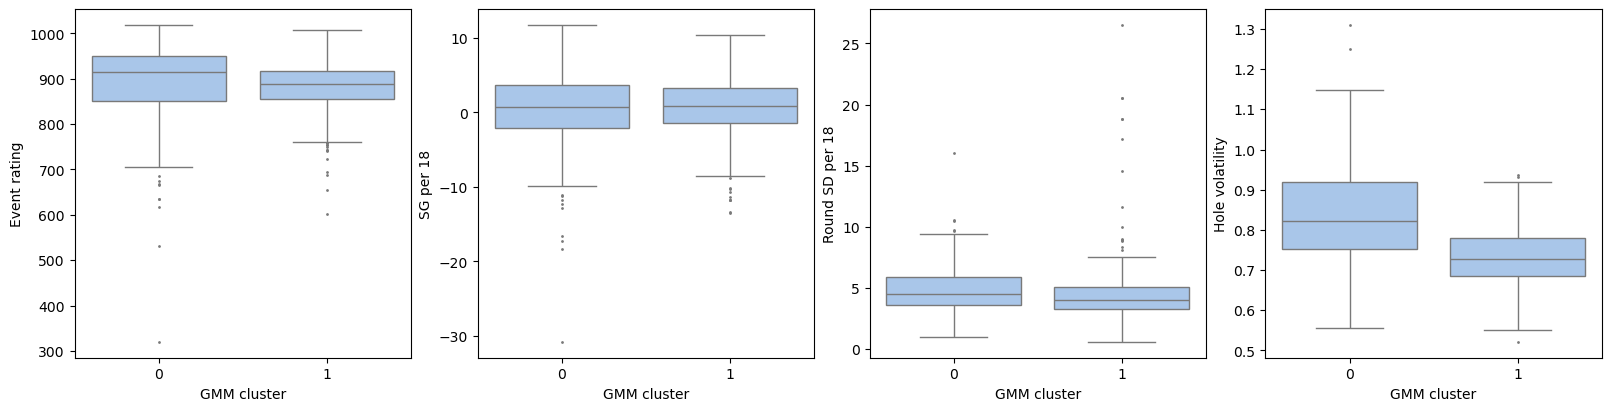

                 rating  sg_per_18  round_sd_18  hole_volatility
rating              1.0       -1.0          1.0              1.0
sg_per_18          -1.0        1.0         -1.0             -1.0
round_sd_18         1.0       -1.0          1.0              1.0
hole_volatility     1.0       -1.0          1.0              1.0


In [12]:
gmm2_labels = models_2['Gaussian mixture'][1]
comparison = profiles_2.loc[cluster_profiles.index, ['rating', 'sg_per_18', 'round_sd_18', 'hole_volatility']].copy()
comparison['cluster'] = gmm2_labels
summary_2 = comparison.groupby('cluster').agg(
    n_players=('rating', 'size'),
    median_rating=('rating', 'median'),
    median_sg_per_18=('sg_per_18', 'median'),
    median_round_sd_18=('round_sd_18', 'median'),
    median_hole_volatility=('hole_volatility', 'median'),
)
display(summary_2.round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)
for ax, column, label in zip(
    axes,
    ['rating', 'sg_per_18', 'round_sd_18', 'hole_volatility'],
    ['Event rating', 'SG per 18', 'Round SD per 18', 'Hole volatility'],
):
    sns.boxplot(data=comparison, x='cluster', y=column, ax=ax, color='#9ec5f4', fliersize=1)
    ax.set(xlabel='GMM cluster', ylabel=label)
plt.show()

print(comparison.groupby('cluster')[['rating', 'sg_per_18', 'round_sd_18', 'hole_volatility']].mean().corr().round(2))

## Friday figures: profiles by cluster and clusters against rating

These figures are descriptive rather than proof of distinct archetypes. The profile plot shows which skill-adjusted features differ between clusters; the rating plot shows how much the cluster labels track overall skill.

In [ ]:
## Profiles by cluster
profile_centroids = (cluster_profiles.assign(cluster=gmm2_labels)
                     .groupby('cluster')[STYLE_FEATURES].mean())
profile_centroids_z = (profile_centroids - cluster_profiles[STYLE_FEATURES].mean()) / cluster_profiles[STYLE_FEATURES].std()
profile_labels = [name.removesuffix('_vs_skill').replace('_', ' ') for name in STYLE_FEATURES]
profile_centroids_z.columns = profile_labels

fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(profile_centroids_z, center=0, cmap='RdBu_r', vmin=-1.2, vmax=1.2,
            annot=True, fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Cluster mean z-score'}, ax=ax)
ax.set(xlabel='Skill-adjusted profile feature', ylabel='GMM cluster',
       title='Skill-adjusted player profiles by cluster')
plt.xticks(rotation=35, ha='right')
plt.show()

print('Centroid interpretation: positive values are above the overall retained-player mean.')

In [ ]:
fig.savefig(ROOT / 'Documents' / 'figures' / 'clustering_profile_centroids.png', dpi=180, bbox_inches='tight')

In [ ]:
## Clusters against rating
rating_plot = comparison.copy()
rating_plot['cluster'] = rating_plot['cluster'].astype(str)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
sns.boxplot(data=rating_plot, x='cluster', y='rating', order=['0', '1'], color='#9ec5f4', fliersize=1, ax=axes[0])
sns.stripplot(data=rating_plot, x='cluster', y='rating', order=['0', '1'], color='#184f95', alpha=0.25, size=2.5, ax=axes[0])
axes[0].set(xlabel='GMM cluster', ylabel='Median event-time rating', title='Rating distributions by cluster')

sns.scatterplot(data=rating_plot, x='rating', y='sg_per_18', hue='cluster', hue_order=['0', '1'], palette={'0': '#eb6834', '1': '#1baf7a'}, alpha=0.55, s=28, ax=axes[1])
axes[1].set(xlabel='Median event-time rating', ylabel='SG per 18', title='Clusters against rating and performance')
axes[1].legend(title='GMM cluster', frameon=False)
plt.show()

print('Rating versus cluster summary:')
print(rating_plot.groupby('cluster')[['rating', 'sg_per_18', 'round_sd_18', 'hole_volatility']].median().round(2))

In [ ]:
fig.savefig(ROOT / 'Documents' / 'figures' / 'clustering_rating_comparison.png', dpi=180, bbox_inches='tight')

## Step 3: cluster only on stable skill-adjusted features

The split-half reliability analysis identifies which profile dimensions persist across each player's events. I compare clustering on all residual features with clustering on the more reliable score-mix and consistency dimensions.

In [13]:
stable_features = [
    'pct_birdie_or_better_vs_skill', 'pct_par_vs_skill',
    'pct_bogey_vs_skill', 'pct_double_or_worse_vs_skill',
    'hole_volatility_vs_skill', 'round_sd_18_vs_skill',
]
stable_profiles = profiles_2[stable_features].dropna()
X_stable = StandardScaler().fit_transform(stable_profiles)
stable_models = {}
for model_name in ['K-means', 'Gaussian mixture']:
    if model_name == 'K-means':
        model = KMeans(n_clusters=2, n_init=50, random_state=0)
        labels = model.fit_predict(X_stable)
        score = silhouette_score(X_stable, labels)
    else:
        model = GaussianMixture(n_components=2, n_init=10, reg_covar=1e-5, random_state=0)
        labels = model.fit_predict(X_stable)
        score = silhouette_score(X_stable, labels)
    stable_models[model_name] = (model, labels)
    print(f'{model_name} on stable features: silhouette={score:.3f}; sizes={pd.Series(labels).value_counts().sort_index().to_dict()}')
print(f'GMM agreement, all versus stable features: ARI={adjusted_rand_score(gmm2_labels, stable_models["Gaussian mixture"][1]):.3f}')

K-means on stable features: silhouette=0.262; sizes={0: 386, 1: 218}
Gaussian mixture on stable features: silhouette=0.238; sizes={0: 412, 1: 192}
GMM agreement, all versus stable features: ARI=0.625


## Step 4: sensitivity to the profile threshold

A cluster that only appears under one minimum-data rule is not a robust archetype. Compare the primary 2-event threshold with a stricter 3-event/6-round/108-hole threshold.

In [14]:
profiles_3, _, keep_3 = build_profiles(features, min_events=3, min_rounds=6, min_holes=108)
profiles_3 = add_skill_adjusted(profiles_3)
common_players = profiles_2.index.intersection(profiles_3.index)

def fit_two_cluster_gmm(profile_table, feature_names, index=None):
    data = profile_table[feature_names].dropna()
    if index is not None:
        data = data.loc[data.index.intersection(index)]
    X = StandardScaler().fit_transform(data)
    model = GaussianMixture(n_components=2, n_init=10, reg_covar=1e-5, random_state=0)
    return data.index, model.fit_predict(X)

idx_2, labels_2_common = fit_two_cluster_gmm(profiles_2, STYLE_FEATURES, common_players)
idx_3, labels_3_common = fit_two_cluster_gmm(profiles_3, STYLE_FEATURES, common_players)
print(f'Primary threshold retained: {len(keep_2):,}; stricter threshold retained: {len(keep_3):,}')
print(f'Common players: {len(idx_2):,}; threshold-sensitivity ARI: {adjusted_rand_score(labels_2_common, labels_3_common):.3f}')
print('Stricter threshold cluster sizes:', pd.Series(labels_3_common).value_counts().sort_index().to_dict())

Primary threshold retained: 604; stricter threshold retained: 432
Common players: 432; threshold-sensitivity ARI: 0.893
Stricter threshold cluster sizes: {0: 326, 1: 106}


## Step 5: stability and continuous style dimensions

Finally, bootstrap the two-cluster solution and inspect PCA. High bootstrap agreement would support discrete groups; diffuse PCA structure and unstable assignments would favor reporting continuous style dimensions.

Bootstrap agreement with the original GMM: mean ARI=0.572; median=0.623; minimum=-0.012
PCA explained variance: [0.229 0.168]


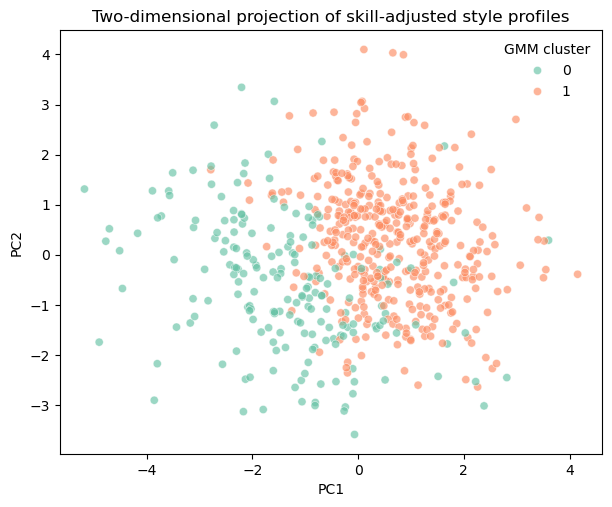

In [15]:
rng = np.random.default_rng(0)
reference_model = models_2['Gaussian mixture'][0]
reference_labels = gmm2_labels
bootstrap_aris = []
for seed in range(50):
    sample_positions = rng.integers(0, len(cluster_profiles), len(cluster_profiles))
    X_boot = X[sample_positions]
    boot_model = GaussianMixture(n_components=2, n_init=5, reg_covar=1e-5, random_state=seed)
    boot_model.fit(X_boot)
    boot_labels_on_original = boot_model.predict(X)
    bootstrap_aris.append(adjusted_rand_score(reference_labels, boot_labels_on_original))
print(f'Bootstrap agreement with the original GMM: mean ARI={np.mean(bootstrap_aris):.3f}; '
      f'median={np.median(bootstrap_aris):.3f}; minimum={np.min(bootstrap_aris):.3f}')

from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
pca_plot = cluster_profiles.copy()
pca_plot['PC1'] = X_pca[:, 0]
pca_plot['PC2'] = X_pca[:, 1]
pca_plot['cluster'] = gmm2_labels
print('PCA explained variance:', pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.scatterplot(data=pca_plot, x='PC1', y='PC2', hue='cluster', hue_order=[0, 1], palette={0: '#eb6834', 1: '#1baf7a'}, alpha=0.65, s=35, ax=ax)
ax.set_title('Two-dimensional projection of skill-adjusted style profiles')
ax.legend(title='GMM cluster', frameon=False)
plt.show()

## Clustering conclusion

The two-cluster solution is a better starting point than the earlier three-cluster solution, but it still does not establish clean archetypes. The GMM and K-means assignments agree only moderately (ARI 0.585), and bootstrap agreement with the original GMM is moderate (mean ARI 0.572). Clustering only on the more reliable score-mix and consistency features improves separation (GMM silhouette 0.238 versus 0.158 using all residual features), while retaining moderate agreement with the all-feature solution (ARI 0.625). The stricter three-event threshold gives similar assignments on common players (ARI 0.893), so the broad split is not driven only by the minimum-data rule.

The PCA projection is diffuse: the first two components explain 22.9% and 16.8% of profile variation. This supports describing the result as a preliminary steady-versus-volatile scoring distinction, with a strong relationship to skill and variance, rather than claiming two sharply separated playing-style archetypes. Continuous style dimensions and stability checks should remain part of the final interpretation.